# LocalizeSORTv2 — sequence run

Runs the pipeline on a LettuceMOTS sequence using **ground-truth detections**, so
tracking quality is isolated from detector quality (stock YOLO weights detect no
lettuce).

GT lives in `data/LettuceMOTS/mot/test/<seq>/gt/gt.txt` for sequences 0003, 0007, 0011.

In [1]:
from collections import defaultdict
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd()
if ROOT.name == "lab":
    ROOT = ROOT.parent

SEQ = "0003"        # 0003 | 0007 | 0011
NUM_FRAMES = 60     # None for the whole sequence

IMAGE_DIR = ROOT / "data/LettuceMOTS/images" / SEQ
GT_PATH = ROOT / "data/LettuceMOTS/mot/test" / SEQ / "gt/gt.txt"
OUT_DIR = ROOT / "lab/outputs"
OUT_DIR.mkdir(parents=True, exist_ok=True)

print(ROOT, IMAGE_DIR.exists(), GT_PATH.exists())

/home/shinobi-owl/IISc/LocalizeSORTv2 True True


## Load frames and ground-truth detections

`gt.txt` is standard MOT: `frame, track_id, x, y, w, h, conf, class, visibility`,
with 1-based frames and top-left `xywh`. Our `Detection` wants xyxy.

In [2]:
from localizesort.schemas import Detection

paths = sorted(IMAGE_DIR.glob("*.png"))[:NUM_FRAMES]
frames = [cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB) for p in paths]

gt_rows = np.loadtxt(GT_PATH, delimiter=",")
gt_dets, gt_ids = defaultdict(list), defaultdict(list)
for frame_no, track_id, x, y, w, h, *_ in gt_rows:
    idx = int(frame_no) - 1
    if idx >= len(frames):
        continue
    gt_dets[idx].append(
        Detection(
            bbox=np.array([x, y, x + w, y + h], dtype=np.float32),
            confidence=1.0,
            class_id=0,
        )
    )
    gt_ids[idx].append(int(track_id))

detections = [gt_dets[i] for i in range(len(frames))]
print(f"{len(frames)} frames {frames[0].shape}, {sum(map(len, detections))} GT boxes")

60 frames (1080, 810, 3), 772 GT boxes


## Run the pipeline

In [3]:
from localizesort import LocalizeSORT

pipeline = LocalizeSORT()
tracks = pipeline.run(frames, detections)

for tr in tracks[:12]:
    print(f"frame {tr.frame_id:3d}  gt={len(detections[tr.frame_id]):3d}  tracked={len(tr.track_ids):3d}  ids={sorted(tr.track_ids)[:10]}")

INFO     StrongSort: det_thresh=0.3, max_age=30, max_obs=50, min_hits=3, iou_threshold=0.3, per_class=False,       
         class_ids=None, asso_func=iou, variable_dt=False

INFO     Downloading osnet_x0_25_msmt17.pt...

Downloading...
From: https://drive.google.com/uc?id=1sSwXSUlj4_tHZequ_iZ8w_Jh0VaRQMqF
To: /home/shinobi-owl/IISc/LocalizeSORTv2/lab/models/.osnet_x0_25_msmt17.pt.f05ed3a6b1b54b06897ed62ed2a65806.part


  0%|          | 0.00/3.06M [00:00<?, ?B/s]

 34%|███▍      | 1.05M/3.06M [00:00<00:00, 7.89MB/s]

...

100%|██████████| 3.06M/3.06M [00:00<00:00, 10.2MB/s]

INFO     /home/shinobi-owl/IISc/LocalizeSORTv2/lab/models/osnet_x0_25_msmt17.pt

INFO     [PID 114839] Found existing ReID weights at                                                               
         /home/shinobi-owl/IISc/LocalizeSORTv2/lab/models/osnet_x0_25_msmt17.pt; skipping download.

INFO     Loaded deployed weights from /home/shinobi-owl/IISc/LocalizeSORTv2/lab/models/osnet_x0_25_msmt17.pt:      
         565/565 required tensors, 100.00% required elements

frame   0  gt= 13  tracked=  0  ids=[]
frame   1  gt= 13  tracked=  0  ids=[]
frame   2  gt= 13  tracked= 13  ids=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
frame   3  gt= 13  tracked= 13  ids=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
frame   4  gt= 13  tracked= 12  ids=[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
frame   5  gt= 13  tracked= 12  ids=[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
frame   6  gt= 13  tracked= 12  ids=[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
frame   7  gt= 14  tracked= 12  ids=[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
frame   8  gt= 14  tracked= 12  ids=[2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
frame   9  gt= 14  tracked= 12  ids=[2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
frame  10  gt= 13  tracked= 13  ids=[2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
frame  11  gt= 13  tracked= 13  ids=[2, 3, 4, 5, 6, 7, 8, 9, 10, 11]


GT identities in window : 26
predicted identities    : 39
mean track length       : 17.4 frames
tracks lasting 1 frame  : 7


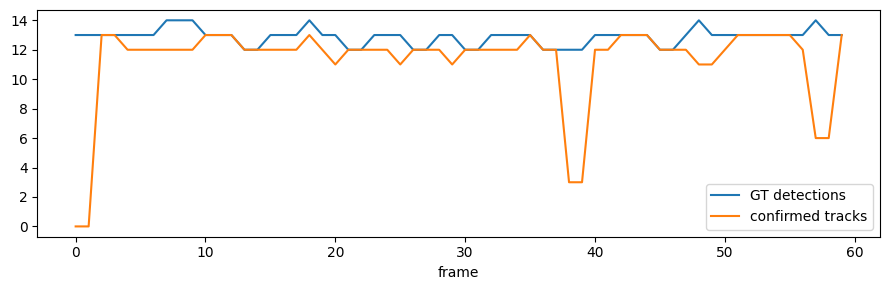

In [4]:
all_ids = {i for tr in tracks for i in tr.track_ids}
lifespan = defaultdict(int)
for tr in tracks:
    for i in tr.track_ids:
        lifespan[i] += 1

gt_total = len({i for ids in gt_ids.values() for i in ids})
print(f"GT identities in window : {gt_total}")
print(f"predicted identities    : {len(all_ids)}")
print(f"mean track length       : {np.mean(list(lifespan.values())):.1f} frames")
print(f"tracks lasting 1 frame  : {sum(v == 1 for v in lifespan.values())}")

plt.figure(figsize=(9, 3))
plt.plot([len(detections[t.frame_id]) for t in tracks], label="GT detections")
plt.plot([len(t.track_ids) for t in tracks], label="confirmed tracks")
plt.xlabel("frame")
plt.legend()
plt.tight_layout()
plt.show()

## Overlay

Box colour is keyed to track ID, so an identity switch shows up as a colour change.

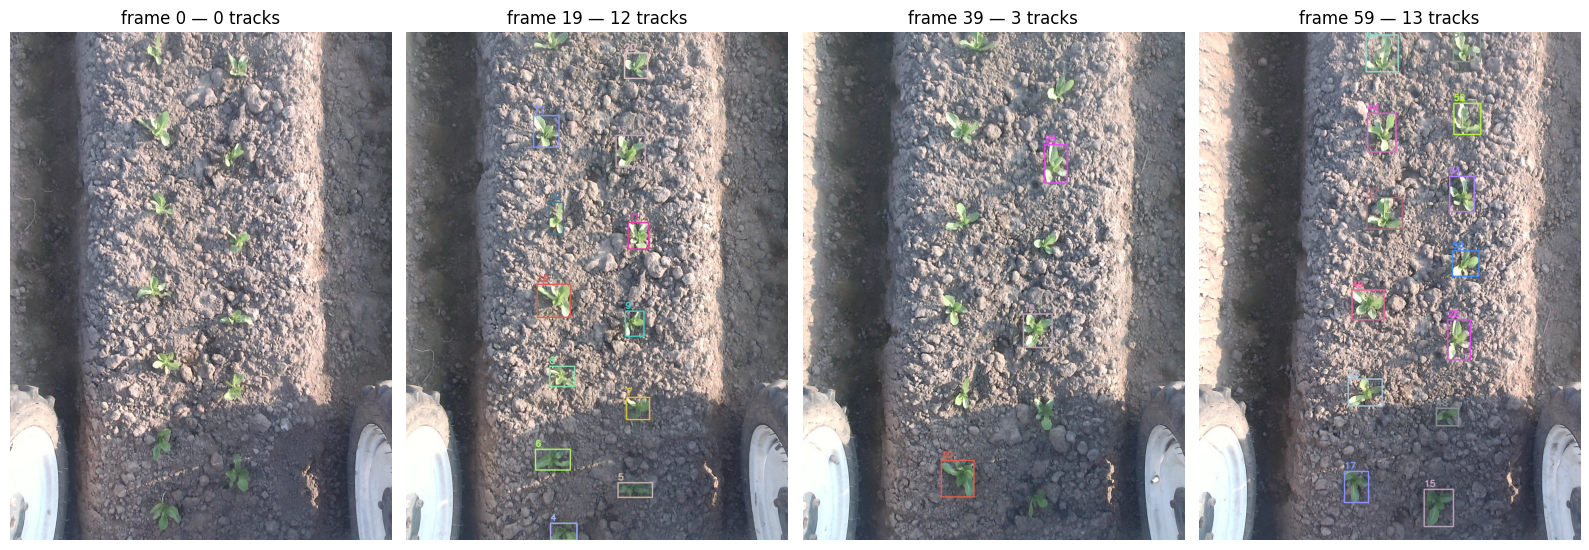

In [5]:
rng = np.random.default_rng(0)
PALETTE = rng.integers(60, 255, size=(256, 3)).tolist()


def overlay(frame, track):
    canvas = frame.copy()
    for det, tid in zip(track.detections, track.track_ids):
        x1, y1, x2, y2 = det.bbox.astype(int)
        color = PALETTE[tid % 256]
        cv2.rectangle(canvas, (x1, y1), (x2, y2), color, 2)
        cv2.putText(canvas, str(tid), (x1, max(y1 - 6, 12)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2)
    return canvas


picks = np.linspace(0, len(tracks) - 1, 4).astype(int)
fig, axes = plt.subplots(1, len(picks), figsize=(16, 7))
for ax, i in zip(axes, picks):
    ax.imshow(overlay(frames[i], tracks[i]))
    ax.set_title(f"frame {i} — {len(tracks[i].track_ids)} tracks")
    ax.axis("off")
plt.tight_layout()
plt.show()

## Write an annotated video

In [6]:
out_path = OUT_DIR / f"{SEQ}_tracked.mp4"
h, w = frames[0].shape[:2]
writer = cv2.VideoWriter(str(out_path), cv2.VideoWriter_fourcc(*"mp4v"), 10, (w, h))
for frame, track in zip(frames, tracks):
    writer.write(cv2.cvtColor(overlay(frame, track), cv2.COLOR_RGB2BGR))
writer.release()
print(out_path, out_path.stat().st_size // 1024, "KB")

/home/shinobi-owl/IISc/LocalizeSORTv2/lab/outputs/0003_tracked.mp4 8896 KB


## Detector path

Same frames through the real Detector. Stock `yolov8n.pt` is COCO-trained, so this
should stay near zero until crop-specific weights are configured.

In [7]:
counts = [len(pipeline.detector(f)) for f in frames[:10]]
print("detections per frame:", counts)

detections per frame: [0, 0, 0, 0, 0, 0, 0, 1, 0, 0]
